<a href="https://colab.research.google.com/github/osen-ifabua/scrambled-shakespeare/blob/main/Investigating_Evolutionary_Optimisation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Investigation of Hamming Distance Model

##Introduction and aim


In this investigation, I designed an experiment based on a model which attempts to evolve a random string into a fixed target string or the "master sequence" (first two lines of a Shakespeare sonnet).

The question:
> How does sequence length affect the performance of this evolutionary optimisation algorithm?

Sequence length of the target determines the number of positions that potentially must be altered to match the target.

My hypothesis:
> the higher the sequence length, the more difficult the matching process

Hence, I expected that increasing L would meant more iterations required to reach the target.

## Implementation of Basic Model
The model measures the closeness of a string to the target, i.e. the fitness, using Hamming distance from the target. Hence, the fittest string has the lowest Hamming distance.

The fittest string selected from *N* random L-length strings produces *N* mutated offspring strings. Each character in a string has a probability *p* of being randomly altered.

This process is iterated for a maximum of *G* generations or until convergence, in this model, when the Hamming distance $\leq{2}$.

### Imports, Master Sequence and Alphabet

In [ ]:
import random
import string
random.seed(42) #to make results reproducible

master = "as an unperfect actor on the stage who with his fear is put beside his part" #First two lines of Sonnet 23 without comma and uppercase

alphabet = string.ascii_lowercase + " "
L = len(master)

### Hamming Distance Function

In [ ]:
# Tallies up number of differences between two strings
def hamming_distance(string1, string2):
  if len(string1) != len(string2):
    raise ValueError("Strings must have equal length")
  return sum(c1 != c2 for c1, c2 in zip(string1, string2))

### Random Sequence Generator

In [ ]:
# Generates random strings of a given length
def generate_random_sequence(length):
  return "".join(random.choice(alphabet) for _ in range(length))

### Mutation Function

In [ ]:
#Iterates through a string and chooses which characters to alter
def mutate(sequence, p):
  new_sequence = []

  #Random alters each character if its probability of mutation as high as given p
  for character in sequence:
    if random.random() < p:
      choices = [c for c in alphabet if c != character]
      new_sequence.append(random.choice(choices))
    else:
      new_sequence.append(character)

  return "".join(new_sequence)

### Generational Evolution Algorithm

In [ ]:
def evolve_until_target(master, N, p, max_generations):

  L = len(master)

  #Creates first N random sequences
  population = [generate_random_sequence(L) for _ in range (N)]

  #Picks the fittest string out of the initial N strings
  parent = min(population, key=lambda x: hamming_distance(x, master))

  #Keeps a list of hamming distances of fittest strings each generation
  history = [hamming_distance(parent, master)]

  for generation in range(1, max_generations + 1):

    #Creates mutated offspring of parent string
    children = [mutate(parent, p) for _ in range(N)]

    #Selects fittest offspring
    fittest_child = min(children, key=lambda c: hamming_distance(c, master))

    #Replaces parent only if offspring improves the distance
    if hamming_distance(fittest_child, master) < hamming_distance(parent, master):
      parent = fittest_child

    distance = hamming_distance(parent, master)
    history.append(distance)

  #Loop breaks if child string has 2 or fewer differences from target
    if distance <= 2:
      return parent, generation, history

  #Returns parameters even if no convergence
  return parent, generation, history


### Running the simulation with desired parameters N, p, G

In [ ]:
#result, generations, history = evolve_until_target(master, N = 10, p = 0.3, max_generations = 10000)

#print("Result: ", result)
#print("Generations: ", generations)
#print("Hamming distance: ", history[-1])

##Designing an Experiment to Investigate Effect of Parameter *L*

I created multiple versions of the master sequence by truncating the full sonnet at seven different lengths.

For each length, I ran the model with all other parameters fixed. I used a fixed random seed to give reproducible results.

The dependent variable I observed was the final Hamming distance.

In [ ]:
#Sonnet 23 stored within a string
full_sonnet = """As an unperfect actor on the stage
Who with his fear is put besides his part,
Or some fierce thing replete with too much rage,
Whose strength's abundance weakens his own heart.
So I, for fear of trust, forget to say5
The perfect ceremony of love's rite,
And in mine own love's strength seem to decay,
O'ercharged with burden of mine own love's might.
O, let my books be then the eloquence
And dumb presagers of my speaking breast,10
Who plead for love and look for recompense
More than that tongue that more hath more express'd.
O, learn to read what silent love hath writ:
To hear with eyes belongs to love's fine wit."""


#Cleaning the complete sonnet text to ensure consistency with model's character set
full_sonnet = full_sonnet.lower() #makes all letters lowercase
full_sonnet = full_sonnet.replace("\n", " ") #turns new lines into single spaces
full_sonnet = "".join(c for c in full_sonnet if c in string.ascii_lowercase or c == " ") #creates a clean string of sonnet text without punctuation

print("Length of clean sonnet: ", len(full_sonnet))

Length of clean sonnet:  595


In [ ]:
#Creating a list of seven different values of L
different_Ls = list(range(85, 596, 85))

test_results = []

#Passing each value of L through the model, keeping other parameters constant
for L in different_Ls:
  master = full_sonnet[:L]

  final_string, generations, history = evolve_until_target(
      master,
      N = 10,
      p = 0.1,
      max_generations = 1000
  )

  #Collating the results of each L-value in a dictionary
  test_results.append({
      "length": L,
      "generations": generations,
      "final_distance": history[-1],
      "final_string": final_string
  })

for r in test_results:
  print(r["length"], r["generations"], r["final_distance"])

85 1000 33
170 1000 102
255 1000 177
340 1000 251
425 1000 326
510 1000 400
595 1000 480


## Results and Visualisations

### Sequence Length vs Final Hamming Distance

<function matplotlib.pyplot.show(close=None, block=None)>

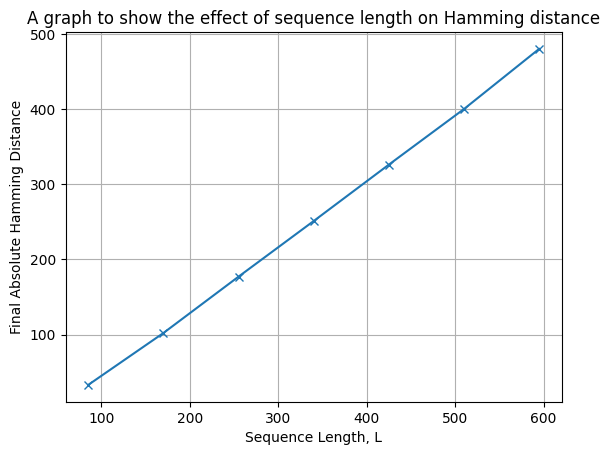

In [ ]:
#Plots a graph of sequence length vs final Hamming distance
import matplotlib.pyplot as plt

lengths = [r["length"] for r in test_results]
distances = [r["final_distance"] for r in test_results]

plt.figure()
plt.plot(lengths, distances, marker = "x")
plt.grid(True)

plt.xlabel("Sequence Length, L")
plt.ylabel("Final Absolute Hamming Distance")
plt.title("A graph to show the effect of sequence length on Hamming distance")

plt.show

###Sequence Length vs Normalised Hamming Distance After 1000 Generations

<function matplotlib.pyplot.show(close=None, block=None)>

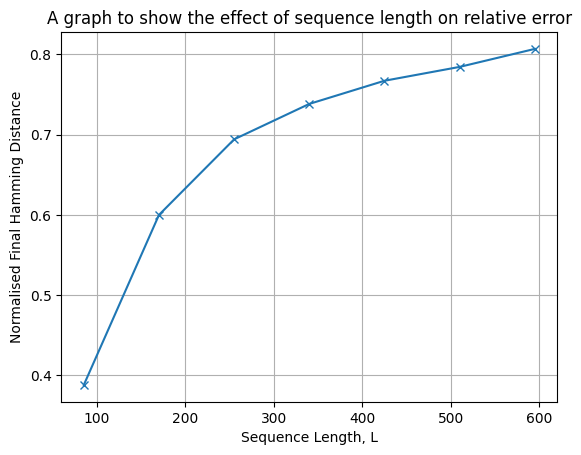

In [ ]:
#Plots a graph of sequence length vs normalised Hamming distance
normalised_hamming_distance = [r["final_distance"] / r["length"] for r in test_results]

plt.figure
plt.plot(lengths, normalised_hamming_distance, marker = "x")
plt.grid(True)

plt.xlabel("Sequence Length, L")
plt.ylabel("Normalised Final Hamming Distance")
plt.title("A graph to show the effect of sequence length on relative error")

plt.show

## Interpretation and Discussion

Graph 1 shows a strong positive correlation and approximately linear relationship between final absolute Hamming distance (raw number of errors after 1000 generations) and sequence length, indicating that as sequence length increases, the strings produced are increasingly less similar to the target. This shows that the model optimises less effectively as the problem size increases.

Graph 2 uses normalised Hamming distance, showing that relative error increases more slowly than absolute error and seemingly stabilises. This indicates that the model matches a consistent proportion of characters across a range of L-values, although the actual number of matches varies.

The final hamming distance values show that the model fails to converge when *G* = 1000 and *N* = 10, indicating that as sequence length increases, the search space grows too significantly for the model to achieve the target sequence exactly within the computational boundaries.

### Limitations and Extensions
To control the experiment, other parameters *p*, *N* and maximum no. of generations were fixed, so the model may not have been perfoming in the optimal conditions for each sequence length, and, in all cases, was terminated when the generation limit was reached instead of when convergence occurred.

Hence, experimenting to determine the optimal values of *p* and *N* and unlimiting the number of generations would allow for comparison to when the model achieves convergence most efficiently.

The model is stochastic as it involves elements of randomness. Using a random seed increases reproducibility yet limits the scope of the results to a single run. Increasing the number of trials for each different values of L would produce more reliable results.

Also, solely using Hamming distance to measure fitness could be too simplistic. Implementing the more flexible Levenshtein distance, which considers insertions and deletions alongside replacement, would facilitate more types of errors and better simulate real-life applications like DNA modelling.

## Conclusions
Overall, these results align with my hypothesis: increasing sequence length makes optimisation more difficult to achieve. The model performs relatively consistently but struggles to produce accurate solutions.